# MC2: Mustererkennung in einer Schweizer QR-Rechnung

**Student:** Haris Salii  
**Land:** Schweiz  
**Semester:** HS26  
**Gewählte Aufgabe:** Klassische Mustererkennung (Tag 6–10)  
**Algorithmus:** Canny-Kantendetektor



## Tag 6: Technische Umsetzung

Der Canny-Kantendetektor wird als explizite Abfolge einzelner Verarbeitungsschritte umgesetzt. Ein einfaches geometrisches Testbild dient ausschliesslich dazu, die korrekte Funktionsweise zu überprüfen. An diesem Tag werden noch kein anwendungsspezifischer Use Case und keine quantitative Evaluation eingeführt.

In [1]:
import base64
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter

plt.rcParams["figure.dpi"] = 110

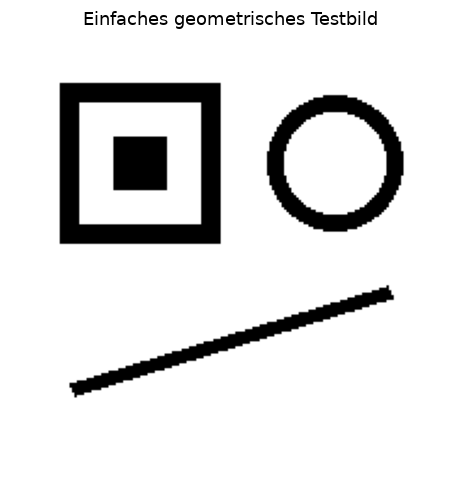

In [2]:
# Einfaches Testbild mit unterschiedlichen geometrischen Begrenzungen
test_image_pil = Image.new("L", (180, 180), color=255)
draw = ImageDraw.Draw(test_image_pil)
draw.rectangle((20, 20, 85, 85), outline=0, width=8)
draw.rectangle((42, 42, 63, 63), fill=0)
draw.ellipse((105, 25, 160, 80), outline=0, width=7)
draw.line((25, 145, 155, 105), fill=0, width=6)
test_image = np.asarray(test_image_pil, dtype=np.uint8)

plt.figure(figsize=(4.5, 4.5))
plt.imshow(test_image, cmap="gray", vmin=0, vmax=255)
plt.title("Einfaches geometrisches Testbild")
plt.axis("off")
plt.tight_layout()

### Explizite Schritte des Algorithmus

1. Die gaußsche Glättung reduziert kleine Intensitätsschwankungen.
2. Sobel-Filter berechnen die horizontalen und vertikalen Gradienten.
3. Gradientenstärke und -richtung beschreiben Stärke und Orientierung jedes lokalen Helligkeitsübergangs.
4. Die Non-Maximum Suppression behält nur lokale Maxima entlang der Gradientenrichtung.
5. Die doppelte Schwellenwertbildung trennt starke und schwache Kantenkandidaten.
6. Die Hysterese behält schwache Kandidaten nur, wenn sie mit einer starken Kante verbunden sind.

In [3]:
SOBEL_X = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype=float)
SOBEL_Y = SOBEL_X.T


def gaussian_smoothing(image, sigma):
    image_8bit = np.asarray(image, dtype=np.uint8)
    blurred = Image.fromarray(image_8bit).filter(ImageFilter.GaussianBlur(radius=sigma))
    return np.asarray(blurred, dtype=float)


def convolve_3x3(image, kernel):
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    height, width = image.shape
    padded = np.pad(image, 1, mode="reflect")
    result = np.zeros_like(image, dtype=float)
    for row in range(3):
        for column in range(3):
            result += kernel[row, column] * padded[row:row + height, column:column + width]
    return result


def non_maximum_suppression(magnitude, direction):
    suppressed = np.zeros_like(magnitude)
    direction_degrees = (np.rad2deg(direction) + 180) % 180

    center = magnitude[1:-1, 1:-1]
    angles = direction_degrees[1:-1, 1:-1]
    output = suppressed[1:-1, 1:-1]

    comparisons = [
        ((angles < 22.5) | (angles >= 157.5), magnitude[1:-1, :-2], magnitude[1:-1, 2:]),
        ((angles >= 22.5) & (angles < 67.5), magnitude[:-2, 2:], magnitude[2:, :-2]),
        ((angles >= 67.5) & (angles < 112.5), magnitude[:-2, 1:-1], magnitude[2:, 1:-1]),
        ((angles >= 112.5) & (angles < 157.5), magnitude[:-2, :-2], magnitude[2:, 2:]),
    ]

    for direction_mask, neighbour_1, neighbour_2 in comparisons:
        keep = direction_mask & (center >= neighbour_1) & (center >= neighbour_2)
        output[keep] = center[keep]
    return suppressed


def dilate_binary(mask):
    mask = np.asarray(mask, dtype=bool)
    height, width = mask.shape
    padded = np.pad(mask, 1, mode="constant", constant_values=False)
    dilated = np.zeros_like(mask)
    for row in range(3):
        for column in range(3):
            dilated |= padded[row:row + height, column:column + width]
    return dilated


def double_threshold_and_hysteresis(suppressed, low_threshold, high_threshold):
    maximum = suppressed.max()
    normalized = suppressed / maximum if maximum > 0 else suppressed.copy()

    strong = normalized >= high_threshold
    weak = (normalized >= low_threshold) & ~strong
    edges = strong.copy()
    remaining_weak = weak.copy()

    while True:
        connected = remaining_weak & dilate_binary(edges)
        if not connected.any():
            break
        edges |= connected
        remaining_weak &= ~connected

    return edges, normalized, strong, weak


def canny_steps(image, sigma, low_threshold, high_threshold):
    smoothed = gaussian_smoothing(image, sigma)
    gradient_x = convolve_3x3(smoothed, SOBEL_X)
    gradient_y = convolve_3x3(smoothed, SOBEL_Y)
    magnitude = np.hypot(gradient_x, gradient_y)
    direction = np.arctan2(gradient_y, gradient_x)
    suppressed = non_maximum_suppression(magnitude, direction)
    edges, normalized, strong, weak = double_threshold_and_hysteresis(
        suppressed, low_threshold, high_threshold
    )
    return {
        "smoothed": smoothed,
        "gradient_x": gradient_x,
        "gradient_y": gradient_y,
        "magnitude": magnitude,
        "direction": direction,
        "suppressed": suppressed,
        "normalized": normalized,
        "strong": strong,
        "weak": weak,
        "edges": edges,
    }


In [4]:
# Parameter nur für die Funktionskontrolle
test_sigma = 1.0
test_low_threshold = 0.20
test_high_threshold = 0.40

test_result = canny_steps(
    test_image,
    sigma=test_sigma,
    low_threshold=test_low_threshold,
    high_threshold=test_high_threshold,
)

print(f"Gauß-Sigma: {test_sigma}")
print(f"Unterer Schwellenwert: {test_low_threshold}")
print(f"Oberer Schwellenwert: {test_high_threshold}")
print(f"Form des Eingabebildes: {test_image.shape}")
print(f"Form des Ergebnisbildes: {test_result['edges'].shape}")

Gauß-Sigma: 1.0
Unterer Schwellenwert: 0.2
Oberer Schwellenwert: 0.4
Form des Eingabebildes: (180, 180)
Form des Ergebnisbildes: (180, 180)


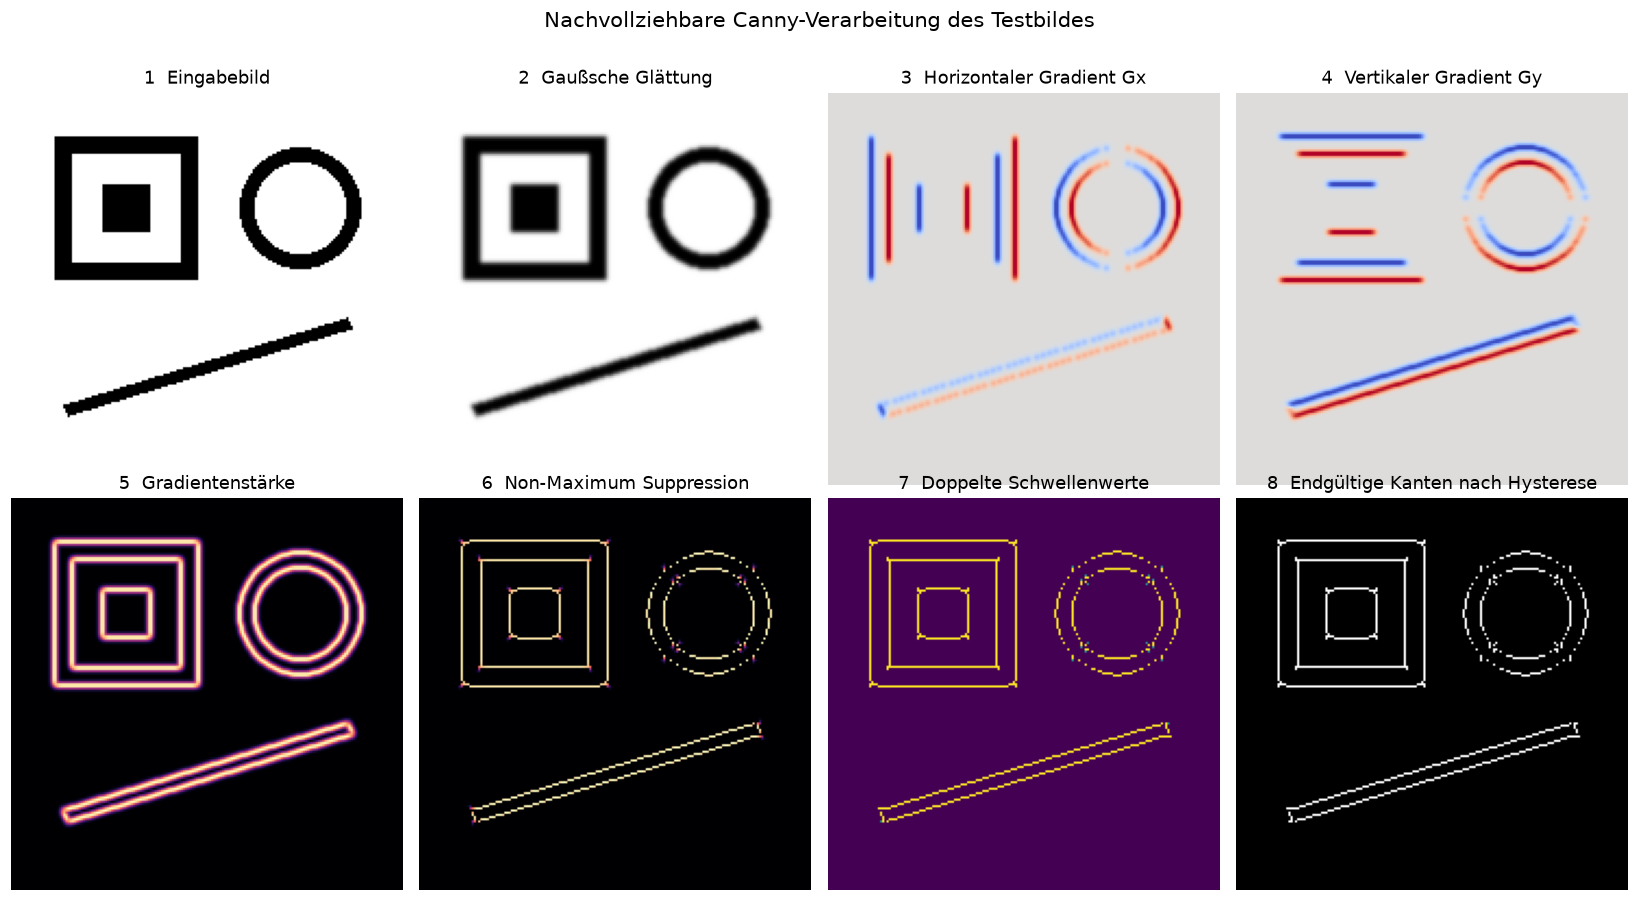

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

visualizations = [
    (test_image, "1  Eingabebild", "gray"),
    (test_result["smoothed"], "2  Gaußsche Glättung", "gray"),
    (test_result["gradient_x"], "3  Horizontaler Gradient Gx", "coolwarm"),
    (test_result["gradient_y"], "4  Vertikaler Gradient Gy", "coolwarm"),
    (test_result["magnitude"], "5  Gradientenstärke", "magma"),
    (test_result["suppressed"], "6  Non-Maximum Suppression", "magma"),
    (test_result["strong"].astype(int) + 0.5 * test_result["weak"].astype(int),
     "7  Doppelte Schwellenwerte", "viridis"),
    (test_result["edges"], "8  Endgültige Kanten nach Hysterese", "gray"),
]

for axis, (image, title, color_map) in zip(axes.ravel(), visualizations):
    axis.imshow(image, cmap=color_map)
    axis.set_title(title)
    axis.axis("off")

fig.suptitle("Nachvollziehbare Canny-Verarbeitung des Testbildes", y=1.02, fontsize=14)
fig.tight_layout()


**Funktionskontrolle:** Die Bildgrösse bleibt während der gesamten Verarbeitung unverändert. Die horizontalen und vertikalen Sobel-Ergebnisse reagieren auf unterschiedliche Kantenrichtungen. Die Non-Maximum Suppression verdünnt die breiten Gradientenreaktionen, und die Hysterese erzeugt zusammenhängende, ungefähr ein Pixel breite Kantenkonturen um die geometrischen Objekte. Damit ist der vorgesehene Aufbau der Implementierung überprüft, ohne bereits die Leistung im späteren Anwendungsfall zu bewerten.

## Tag 7: Daten und Anwendungsgebiet

### Anwendungskontext

Schweizer QR-Rechnungen sind für die digitale Zahlungsabwicklung vorgesehen. Bei einer Smartphone-Aufnahme muss der QR-Bereich zuerst lokalisiert werden, bevor die codierten Zahlungsinformationen gelesen werden können. Besonders relevant sind die drei grossen quadratischen Suchmuster. Ihre horizontalen und vertikalen Begrenzungen liefern sichtbare Anker für Position und Ausrichtung des Swiss QR-Codes.

### Problemstellung und Ziel

Ein Kamerabild kann weichere Übergänge, Kompressionsartefakte oder kleine Intensitätsschwankungen enthalten. Dadurch können Kantenpixel an den schwarz-weissen Modulen unterbrochen oder zusätzlich erzeugt werden. Das analytische Ziel besteht deshalb darin, die Begrenzungen der drei quadratischen Suchmuster als zusammenhängende Kantenstrukturen zu extrahieren. Es handelt sich um eine Aufgabe zur Extraktion von Begrenzungen; das Decodieren der Zahlungsinformationen ist nicht Bestandteil dieses Versuchs.

### Herkunft des Bildes

Das repräsentative Bild ist dasselbe offizielle Beispiel wie bei Tag 1–5: **„Nr. 1 englisch.jpg“** aus dem SIX-Paket *Samples of the QR-bill – payment part*. Verwendet wird ein fester Ausschnitt von 300 × 300 Pixeln um den Swiss QR-Code. Die Quelle ist geeignet, weil sie ein offizielles Schweizer Zahlungsbeispiel darstellt und genau die geometrischen Strukturen enthält, die der gewählte Algorithmus benötigt.

Quelle: [SIX-Beispielpaket](https://www.six-group.com/dam/download/banking-services/standardization/qr-bill/samples-payment-part-en.zip)

Bildform: (300, 300, 3)
Zielmuster: Begrenzungen der drei quadratischen Suchmuster


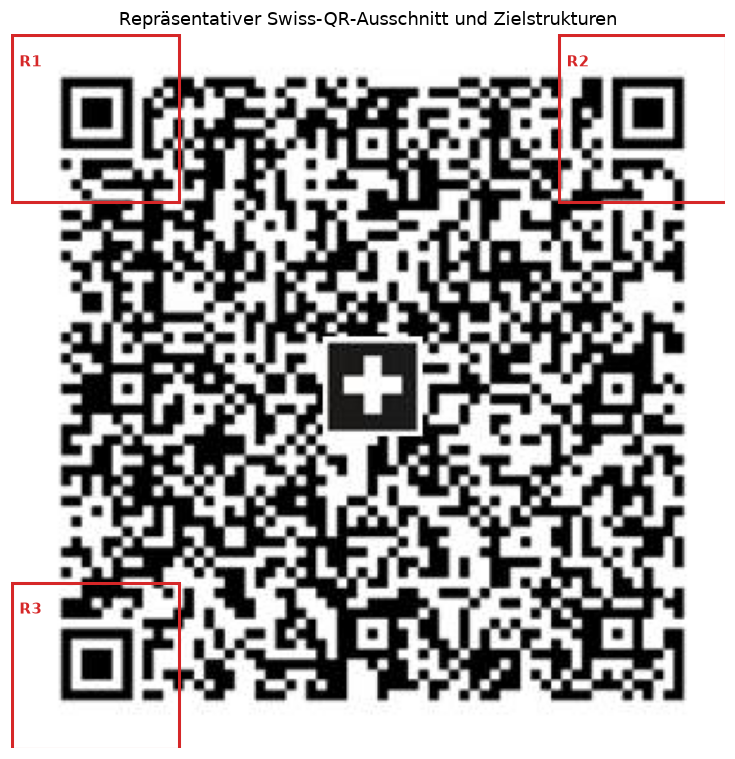

In [6]:
QR_CROP_PNG_BASE64 = "..."

qr_image = Image.open(BytesIO(base64.b64decode(QR_CROP_PNG_BASE64))).convert("RGB")
qr_rgb = np.asarray(qr_image)
qr_gray = np.asarray(qr_image.convert("L"), dtype=np.uint8)

# Feste Bereiche mit den drei Suchmustern; hier findet noch keine Erkennung statt.
finder_regions = [
    (0, 0, 70, 70),
    (230, 0, 300, 70),
    (0, 230, 70, 300),
]

fig, axis = plt.subplots(figsize=(7, 7))
axis.imshow(qr_rgb)
for number, (left, top, right, bottom) in enumerate(finder_regions, start=1):
    rectangle = plt.Rectangle(
        (left, top), right - left, bottom - top,
        fill=False, edgecolor="#d62728", linewidth=2
    )
    axis.add_patch(rectangle)
    axis.text(left + 3, top + 13, f"R{number}", color="#d62728", weight="bold")
axis.set_title("Repräsentativer Swiss-QR-Ausschnitt und Zielstrukturen")
axis.axis("off")
fig.tight_layout()

print(f"Bildform: {qr_rgb.shape}")
print("Zielmuster: Begrenzungen der drei quadratischen Suchmuster")


### Relevante Bildeigenschaften

- Das Bild besitzt einen starken lokalen Schwarz-Weiss-Kontrast, wodurch an den Modulgrenzen grosse Intensitätsgradienten entstehen.
- Die kleinsten Module sind nur ungefähr 4–5 Pixel breit. Eine zu starke Glättung könnte deshalb benachbarte Strukturen verbinden.
- Die Suchmuster bestehen aus ineinanderliegenden horizontalen und vertikalen quadratischen Begrenzungen. Ihre geschlossene, regelmässige Geometrie unterscheidet sich von den kleineren und unregelmässigeren Datenmodulen.
- JPEG-bedingte Intensitätsübergänge und benachbarte Module können zusätzliche Kantenkandidaten erzeugen. Der Detektor soll die starken Begrenzungen der Suchmuster erhalten, ohne jeden schwachen Übergang zu akzeptieren.

Diese Eigenschaften verbinden die Daten explizit mit dem Ziel: Das Bild enthält erkennbare, kontrastreiche Begrenzungen, während die geringe räumliche Grösse der Module die Wahl von Glättung und Schwellenwerten einschränkt.


## Tag 8: Methodisches Design

### Gewähltes Vorgehen

Canny ist geeignet, weil die Zielstrukturen durch lokale Übergänge zwischen schwarzen und weissen Pixeln definiert sind. Die gaußsche Glättung reduziert kleine Intensitätsschwankungen, bevor die Sobel-Gradienten Kantenstärke und -richtung bestimmen. Die Non-Maximum Suppression wandelt breite Gradientenreaktionen in dünne Kandidaten um. Anschliessend behalten die doppelte Schwellenwertbildung und die Hysterese schwache Pixel nur dann, wenn sie mit starken Begrenzungen verbunden sind.

Eine einzelne Kante ist lediglich ein lokaler Helligkeitsübergang. Die beabsichtigte geometrische Struktur besteht dagegen aus zusammenhängenden horizontalen und vertikalen Kanten, welche die ineinanderliegenden quadratischen Begrenzungen eines Suchmusters bilden. Canny übernimmt die Kantenextraktion. Die festen Bereiche R1–R3 beschränken die Evaluation auf die drei für die QR-Lokalisierung relevanten Strukturen. Bewertet wird die Extraktion der Begrenzungen, nicht die vollständige QR-Erkennung.

### Schlüsselparameter und Konfigurationen

Der Gauß-Parameter bleibt bei $\sigma=1{,}0$ Pixel. Dies reduziert kleine JPEG-Übergänge, bleibt aber deutlich unter der ungefähren Modulbreite von 4–5 Pixeln. Variiert werden die beiden normalisierten Schwellenwerte, da sie direkt bestimmen, welche unterdrückten Gradientenreaktionen in die Hysterese gelangen.

| Konfiguration | $\sigma$ | Unterer Schwellenwert | Oberer Schwellenwert | Erwartete Wirkung |
|---|---:|---:|---:|---|
| C0 Ausgangswert | 1,0 | 0,20 | 0,40 | Dominante Begrenzungen erhalten und schwache Übergänge verwerfen |
| C1 Sensitiv | 1,0 | 0,03 | 0,08 | Mehr schwache Reaktionen akzeptieren; höhere Abdeckung, aber mehr zusätzliche Kanten |
| C2 Konservativ | 1,0 | 0,65 | 0,85 | Nur sehr starke Reaktionen behalten; saubereres Ergebnis, aber möglicherweise fehlende Begrenzungen |

C1 und C2 prüfen gezielt die beiden Richtungen des Zielkonflikts um C0. Nur das Schwellenwertpaar ändert sich. Unterschiede lassen sich dadurch der Kantenauswahl und nicht einer veränderten Glättung zuordnen. An diesem Tag werden keine Implementierung und keine Ergebnisse eingeführt.

## Tag 9: Evaluation

### Gewählte quantitative Kennzahl: Grenzlinien-F1-Score

Es wird genau eine abschliessende Kennzahl ausgewiesen: der **Grenzlinien-F1-Score**. Aus dem sauberen offiziellen Bild wird eine Referenzmaske erzeugt, indem das Bild bei 128 binarisiert und jeder Übergang zwischen benachbarten schwarzen und weissen Pixeln markiert wird. Die Auswertung ist auf die drei zuvor festgelegten Bereiche der Suchmuster beschränkt.

Ein erkanntes Kantenpixel gilt als Treffer, wenn es höchstens ein Pixel von einer Referenzbegrenzung entfernt liegt. Dieselbe Toleranz wird in umgekehrter Richtung angewendet. Precision und Recall dienen nur als Zwischengrössen für die Berechnung der einzigen ausgewiesenen Kennzahl:

$$F_1=\frac{2PR}{P+R}.$$

Der Wert liegt zwischen 0 und 1. Ein hoher Wert verlangt sowohl wenige zusätzliche Erkennungen als auch eine breite Abdeckung der Referenzbegrenzungen. Diese Kennzahl ist geeigneter als eine reine Kantenzählung, weil sie berücksichtigt, ob die erkannten Pixel tatsächlich an den beabsichtigten Begrenzungen der Suchmuster liegen.


In [7]:
def binary_boundary(binary_mask):
    binary_mask = np.asarray(binary_mask, dtype=bool)
    boundary = np.zeros_like(binary_mask)

    horizontal_change = binary_mask[:, 1:] != binary_mask[:, :-1]
    boundary[:, 1:] |= horizontal_change
    boundary[:, :-1] |= horizontal_change

    vertical_change = binary_mask[1:, :] != binary_mask[:-1, :]
    boundary[1:, :] |= vertical_change
    boundary[:-1, :] |= vertical_change
    return boundary


def boundary_f1(reference, detected, evaluation_region, tolerance=1):
    reference = np.asarray(reference, dtype=bool) & evaluation_region
    detected = np.asarray(detected, dtype=bool) & evaluation_region

    expanded_reference = reference.copy()
    expanded_detected = detected.copy()
    for _ in range(tolerance):
        expanded_reference = dilate_binary(expanded_reference)
        expanded_detected = dilate_binary(expanded_detected)

    matched_detected = np.logical_and(detected, expanded_reference).sum()
    matched_reference = np.logical_and(reference, expanded_detected).sum()

    precision = matched_detected / detected.sum() if detected.sum() else 0.0
    recall = matched_reference / reference.sum() if reference.sum() else 0.0
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


reference_boundary = binary_boundary(qr_gray < 128)
evaluation_region = np.zeros_like(reference_boundary, dtype=bool)
for left, top, right, bottom in finder_regions:
    evaluation_region[top:bottom, left:right] = True

configurations = {
    "C0 Ausgangswert": {"sigma": 1.0, "low": 0.20, "high": 0.40},
    "C1 Sensitiv": {"sigma": 1.0, "low": 0.03, "high": 0.08},
    "C2 Konservativ": {"sigma": 1.0, "low": 0.65, "high": 0.85},
}

edge_results = {}
rows = []
for name, parameters in configurations.items():
    result = canny_steps(
        qr_gray,
        sigma=parameters["sigma"],
        low_threshold=parameters["low"],
        high_threshold=parameters["high"],
    )
    edge_results[name] = result["edges"]
    score = boundary_f1(reference_boundary, result["edges"], evaluation_region, tolerance=1)
    rows.append({"Konfiguration": name, "Grenzlinien-F1": score})

evaluation = pd.DataFrame(rows)
baseline_score = evaluation.loc[evaluation["Konfiguration"] == "C0 Ausgangswert", "Grenzlinien-F1"].iloc[0]
evaluation["Differenz zu C0"] = evaluation["Grenzlinien-F1"] - baseline_score
evaluation["Relative Änderung (%)"] = 100 * evaluation["Differenz zu C0"] / baseline_score

print(evaluation.to_string(index=False, formatters={
    "Grenzlinien-F1": lambda value: f"{value:.4f}",
    "Differenz zu C0": lambda value: f"{value:+.4f}",
    "Relative Änderung (%)": lambda value: f"{value:+.2f}",
}))


  Konfiguration Grenzlinien-F1 Differenz zu C0 Relative Änderung (%)
C0 Ausgangswert         0.9997         +0.0000                 +0.00
    C1 Sensitiv         0.9839         -0.0159                 -1.59
 C2 Konservativ         0.9395         -0.0602                 -6.03


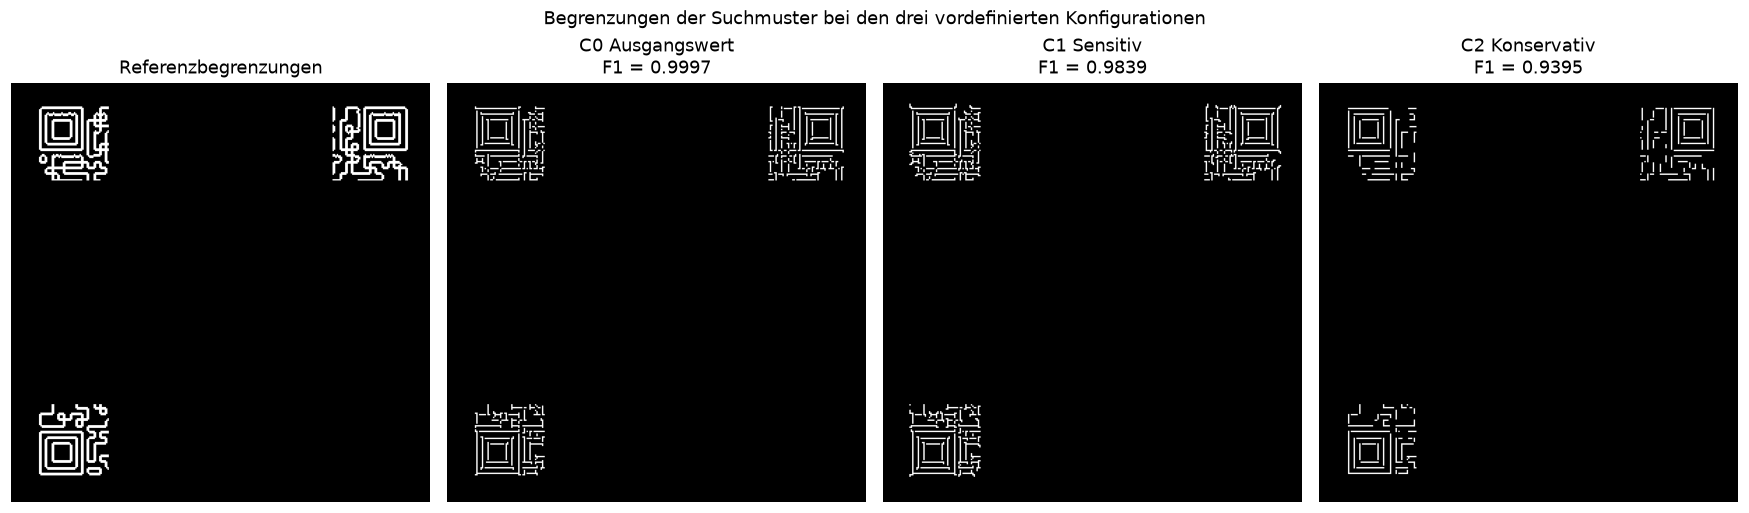

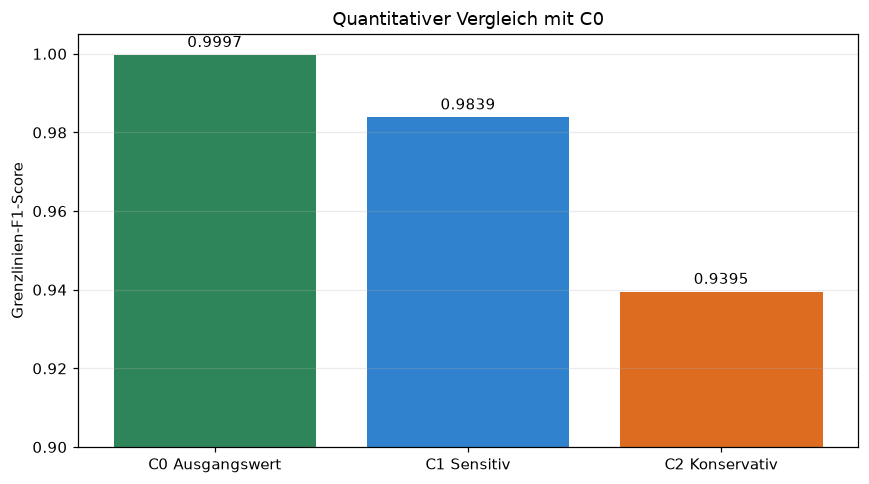

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

axes[0].imshow(reference_boundary & evaluation_region, cmap="gray")
axes[0].set_title("Referenzbegrenzungen")
axes[0].axis("off")

for axis, (name, edges) in zip(axes[1:], edge_results.items()):
    axis.imshow(edges & evaluation_region, cmap="gray")
    score = evaluation.loc[evaluation["Konfiguration"] == name, "Grenzlinien-F1"].iloc[0]
    axis.set_title(f"{name}\nF1 = {score:.4f}")
    axis.axis("off")

fig.suptitle("Begrenzungen der Suchmuster bei den drei vordefinierten Konfigurationen", y=1.03)
fig.tight_layout()

fig, axis = plt.subplots(figsize=(8, 4.5))
colors = ["#2f855a", "#3182ce", "#dd6b20"]
bars = axis.bar(evaluation["Konfiguration"], evaluation["Grenzlinien-F1"], color=colors)
axis.set_ylabel("Grenzlinien-F1-Score")
axis.set_ylim(0.90, 1.005)
axis.set_title("Quantitativer Vergleich mit C0")
axis.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, evaluation["Grenzlinien-F1"]):
    axis.text(bar.get_x() + bar.get_width() / 2, value + 0.002, f"{value:.4f}", ha="center")
fig.tight_layout()

### Quantitativer Vergleich

C0 liegt mit einem Grenzlinien-F1-Score von **0,9997** auf Rang 1. Danach folgen C1 mit **0,9839** und C2 mit **0,9395**. Gegenüber C0 verändert sich C1 um **−0,0159** beziehungsweise **−1,59 %**, während sich C2 um **−0,0602** beziehungsweise **−6,03 %** verändert. Für alle drei vordefinierten Konfigurationen werden derselbe Grenzlinien-F1-Score und dieselbe Toleranz von einem Pixel verwendet.

## Tag 10: Analyse und Kommunikation

### Beobachtungen

C0 erreicht mit 0,9997 den höchsten Grenzlinien-F1-Score. C1 erzielt 0,9839 und liegt damit 1,59 % unter C0. C2 weist mit 0,9395 den tiefsten Wert auf und liegt 6,03 % unter dem Ausgangswert.

### Interpretation

C0 bietet ein ausgewogenes Verhältnis zwischen Abdeckung der Begrenzungen und Unterdrückung schwacher Übergänge. Bei C1 lassen die niedrigen Schwellenwerte zusätzliche Reaktionen von geglätteten Pixeln, JPEG-Übergängen und benachbarten QR-Modulen durch die Hysterese gelangen. Diese zusätzlichen Pixel verringern die Übereinstimmung mit der Referenz. C2 behält nur die stärksten Übergänge. Dadurch gehen schwächere Abschnitte der ineinanderliegenden quadratischen Begrenzungen verloren, was den grösseren Rückgang erklärt.

### Diskussion und kritische Reflexion

Für dieses offizielle Bild einer Schweizer QR-Rechnung ist C0 am geeignetsten, weil die geometrischen Anker mit wenigen zusätzlichen Kanten erhalten bleiben. Canny extrahiert jedoch nur Kanten; der Algorithmus gruppiert sie weder zu vollständigen Suchmustern noch decodiert er Zahlungsdaten. Perspektivische Verzerrung, Schatten und Bewegungsunschärfe wurden nicht untersucht. Ausserdem stammt die Referenzmaske aus demselben sauberen Bild und wäre beim realen Scannen nicht verfügbar. Die Toleranz von einem Pixel macht den Score zudem weniger empfindlich gegenüber sehr kleinen Lokalisierungsfehlern. Der Versuch belegt deshalb eine zuverlässige Begrenzungsextraktion unter kontrollierten Bedingungen, aber noch keine vollständige Zuverlässigkeit im praktischen Einsatz.

Quellen und Reproduzierbarkeit
- Datengrundlage: SIX, Samples of the QR-bill – payment part, Beispiel „Nr. 1 englisch.jpg“.
- Der repräsentative Ausschnitt von 300 × 300 Pixeln ist im Notebook eingebettet, damit die Analyse ohne lokalen Bildpfad reproduziert werden kann.
- Die Canny-Verarbeitung wird mit NumPy und Pillow explizit umgesetzt; es wird keine fertige Canny-Funktion als Blackbox verwendet.
- Alle Konfigurationen verwenden dasselbe Bild, denselben Glättungswert, dieselben Bereiche der Suchmuster, dieselbe Referenzerzeugung, dieselbe Toleranz und dieselbe Evaluationskennzahl.

Einsatz von KI
Für die Bearbeitung wurde OpenAI ChatGPT/Codex eingesetzt. Die KI unterstützte bei der Strukturierung der Aufgaben und Überprüfung von Python-Code sowie bei der sprachlichen Überarbeitung. Alle Codezellen wurden ausgeführt und die Resultate anhand der erzeugten Visualisierungen und Kennzahlen kontrolliert. Die Inhalte wurden an die Aufgabenstellung und den verwendeten Datensatz angepasst. Die Verantwortung für die endgültige Auswahl, Interpretation und Abgabe liegt beim Autor.